## If Jake Elliott has an 85% success rate on field goals over 50 yards, what is the probability that he makes exactly 4 out of 6 in each quarter per game?

1. Were trying to see if Elliott can make 4 field goals in each quarter
2. The outcome would be out of 6 tries 

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math 
import statistics
import random

In [11]:
rng = np.random.default_rng()

In [12]:
import math
from scipy import stats
def field_goal_probability(p=0.85, n=6, k=4, quarters=4):
    combinations = math.comb(n, k)

    prob_one_quarter = combinations * (p**k) * ((1 - p) ** (n - k))

    prob_full_game = prob_one_quarter**quarters

    return prob_one_quarter, prob_full_game

In [13]:
prob_quarter, prob_game = field_goal_probability()

print(f"Probability in a single quarter: {prob_quarter:.6f} ({prob_quarter:.2%})")
print(f"Probability across all 4 quarters: {prob_game:.8f} ({prob_game:.4%})")

prob_quarter_scipy = stats.binom.pmf(k=4, n=6, p=0.85)
prob_game_scipy = prob_quarter_scipy**4

Probability in a single quarter: 0.176177 (17.62%)
Probability across all 4 quarters: 0.00096338 (0.0963%)


## Mean

In [14]:
data = [12, 15, 14, 10, 8, 18, 22, 19, 13, 17]
mean_val = statistics.mean(data)
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

In [15]:
categories = ["Group A", "Group B", "Group C", "Group D", "Group E"]
values = [23, 45, 12, 38, 32]
mean_value = sum(values) / len(values)

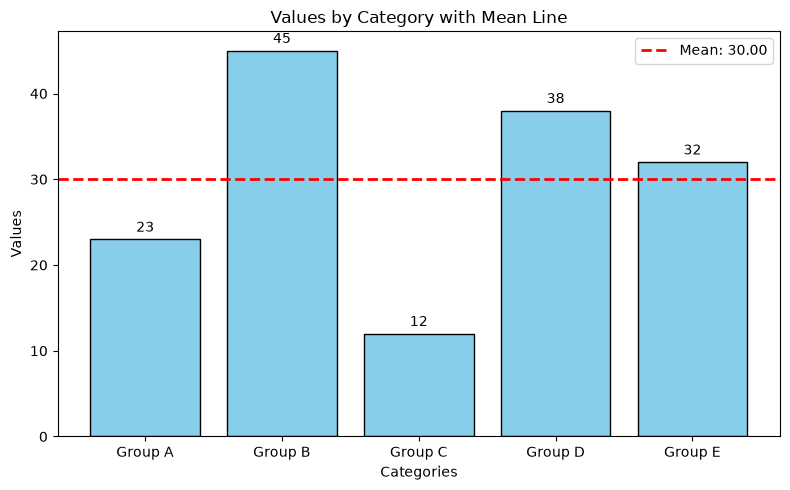

In [16]:
plt.figure(figsize=(8, 5))
bars = plt.bar(categories, values, color="skyblue", edgecolor="black")
plt.axhline(
    y=mean_value,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_value:.2f}",
)
plt.xlabel("Categories")
plt.ylabel("Values")
plt.title("Values by Category with Mean Line")
plt.legend()
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.5,
        f"{yval}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

## Standard Deviation

In [17]:
categories = ["Group A", "Group B", "Group C", "Group D", "Group E"]
values = [23, 45, 12, 38, 32]
mean_value = np.mean(values)
std_dev = np.std(values, ddof=1)  # ddof=1 calculates sample standard deviation

print(f"Mean: {mean_value:.2f}")
print(f"Standard Deviation: {std_dev:.2f}")

Mean: 30.00
Standard Deviation: 12.90


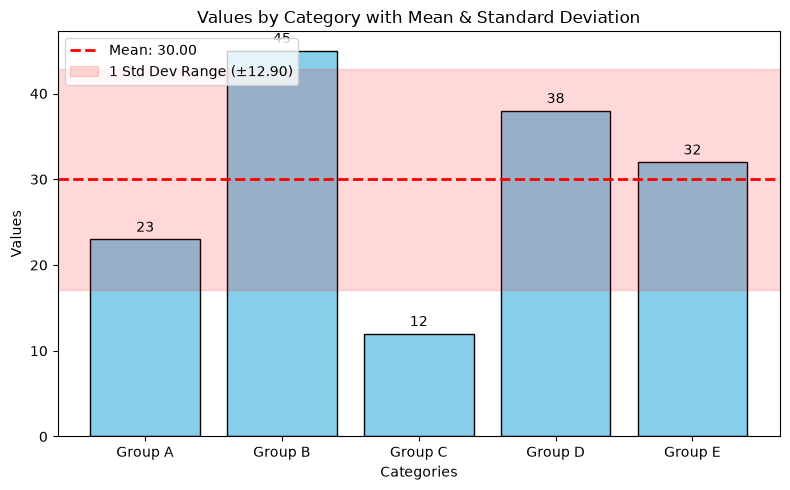

In [18]:
plt.figure(figsize=(8, 5))
bars = plt.bar(categories, values, color="skyblue", edgecolor="black")
plt.axhline(
    y=mean_value,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_value:.2f}",
)
plt.axhspan(
    mean_value - std_dev,
    mean_value + std_dev,
    color="red",
    alpha=0.15,
    label=f"1 Std Dev Range (±{std_dev:.2f})",
)
plt.xlabel("Categories")
plt.ylabel("Values")
plt.title("Values by Category with Mean & Standard Deviation")
plt.legend(loc="upper left")
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.5,
        f"{yval}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

## Empirical Probability

In [21]:
num_trials = 1000
success_rate_true = 0.85
trials = [
    1 if random.random() < success_rate_true else 0 for _ in range(num_trials)
]

In [22]:
makes = trials.count(1)
misses = trials.count(0)

prob_make_empirical = makes / num_trials
prob_miss_empirical = misses / num_trials

print(f"Total Trials: {num_trials}")
print(f"Makes: {makes} | Empirical Probability: {prob_make_empirical:.4f}")
print(f"Misses: {misses} | Empirical Probability: {prob_miss_empirical:.4f}")

Total Trials: 1000
Makes: 824 | Empirical Probability: 0.8240
Misses: 176 | Empirical Probability: 0.1760


In [23]:
outcomes = ["Made FG (1)", "Missed FG (0)"]
empirical_probs = [prob_make_empirical, prob_miss_empirical]
counts = [makes, misses]

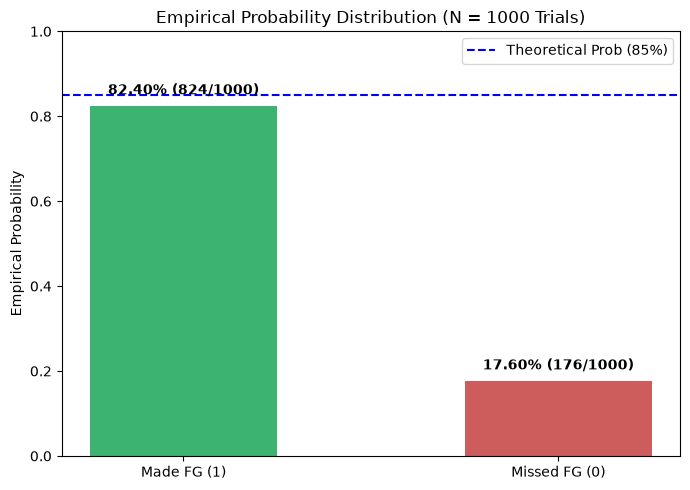

In [27]:
plt.figure(figsize=(7, 5))
bars = plt.bar(
    outcomes, empirical_probs, color=["mediumseagreen", "indianred"], width=0.5
)
plt.axhline(
    y=0.85,
    color="blue",
    linestyle="--",
    linewidth=1.5,
    label="Theoretical Prob (85%)",
)
plt.ylabel("Empirical Probability")
plt.ylim(0, 1.0)
plt.title(f"Empirical Probability Distribution (N = {num_trials} Trials)")
plt.legend(loc="upper right")
for bar, count in zip(bars, counts):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.2%} ({count}/{num_trials})",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

## Theoretical Probability

In [28]:
sample_space = [1, 2, 3, 4, 5, 6]
total_outcomes = len(sample_space)

In [29]:
favorable_outcomes = [x for x in sample_space if x % 2 == 0]
num_favorable = len(favorable_outcomes)
prob_theoretical = num_favorable / total_outcomes

In [30]:
print(f"Sample Space: {sample_space}")
print(f"Favorable Outcomes (Even): {favorable_outcomes}")
print(f"Theoretical Probability: {prob_theoretical:.4f} ({prob_theoretical:.2%})")

Sample Space: [1, 2, 3, 4, 5, 6]
Favorable Outcomes (Even): [2, 4, 6]
Theoretical Probability: 0.5000 (50.00%)


In [31]:
num_rolls = 1000
rolls = [random.choice(sample_space) for _ in range(num_rolls)]
even_rolls_count = sum(1 for roll in rolls if roll % 2 == 0)
prob_empirical = even_rolls_count / num_rolls

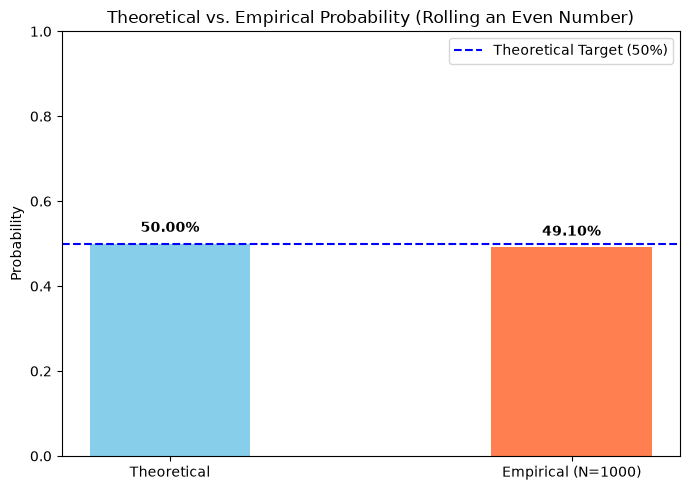

In [32]:
categories = ["Theoretical", "Empirical (N=1000)"]
probabilities = [prob_theoretical, prob_empirical]

plt.figure(figsize=(7, 5))
bars = plt.bar(
    categories, probabilities, color=["skyblue", "coral"], width=0.4
)

plt.axhline(
    y=prob_theoretical,
    color="blue",
    linestyle="--",
    linewidth=1.5,
    label=f"Theoretical Target ({prob_theoretical:.0%})",
)

plt.ylabel("Probability")
plt.ylim(0, 1.0)
plt.title("Theoretical vs. Empirical Probability (Rolling an Even Number)")
plt.legend(loc="upper right")
# Add percentage text labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.2%}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

## Concusion

On the graph we can see that the theoretical probability is on the 50% probability for Jake Elliott making 4 out of 6 field goals every quater per game while the empirical probabilty is 49.10% which is lower. The mean of the graphs are 30 which is the average amount of kicks Jake Elliott makes during each quater and game. And we can see that the standard deviation of the average is 12.90 above and below the mean. Which tells us that Jake Elliott makes 50/50 out of his field goals each game. But in the Empircial Probability we can see that Elliott makes 82.40% of hsi field goals while the remaining 17.60% he misses his field goals so the majority of this data is where Elliott makes all his field goals. 